In [19]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [35]:
PLOTS_PATH = os.path.join(DATA_PATH, "Plots")

analysis_folders = [
    "01_Initial_Exploration",
    "02_Zero_Values_Analysis",
    "03_Negative_Values_Analysis",
    "04_Positive_Values_Analysis",
    "05_Spatial_Analysis"
]

for folder in analysis_folders:
    os.makedirs(os.path.join(PLOTS_PATH, folder), exist_ok=True)

print("Analysis folders created successfully!")

Analysis folders created successfully!


In [20]:
DATA_PATH = r"C:\Users\basma\Downloads\The-Stars-NASA-Space-App-Project\Data\Data_Earth"

print("Folder exists:", os.path.exists(DATA_PATH))
print("Files:", os.listdir(DATA_PATH))

Folder exists: True
Files: ['s01w047.hgt', 's01w047.num', 's01w047.swb']


In [21]:
files_info = []

for filename in os.listdir(DATA_PATH):

    filepath = os.path.join(DATA_PATH, filename)

    if os.path.isfile(filepath):

        file_size = os.path.getsize(filepath)

        files_info.append({
            "File_Name": filename,
            "Extension": os.path.splitext(filename)[1],
            "Size_Bytes": file_size,
            "Size_MB": round(file_size / (1024 ** 2), 3)
        })

files_df = pd.DataFrame(files_info)

files_df

,File_Name,Extension,Size_Bytes,Size_MB
0,s01w047.hgt,.hgt,25934402,24.733
1,s01w047.num,.num,12967201,12.366
2,s01w047.swb,.swb,12967201,12.366


In [22]:
hgt_path = os.path.join(DATA_PATH, "s01w047.hgt")
num_path = os.path.join(DATA_PATH, "s01w047.num")
swb_path = os.path.join(DATA_PATH, "s01w047.swb")

In [23]:
# Read HGT
hgt = np.fromfile(hgt_path, dtype=">i2")

# Read NUM
num = np.fromfile(num_path, dtype=np.uint8)

# Read SWB
swb = np.fromfile(swb_path, dtype=np.uint8)

print("HGT:", hgt.shape)
print("NUM:", num.shape)
print("SWB:", swb.shape)

HGT: (12967201,)
NUM: (12967201,)
SWB: (12967201,)


In [24]:
hgt_df = pd.DataFrame(hgt)
num_df = pd.DataFrame(num)
swb_df = pd.DataFrame(swb)

In [25]:
hgt_df.head()

,0
0,0
1,0
2,0
3,0
4,0


In [26]:
num_df.head()

,0
0,0
1,0
2,0
3,0
4,0


In [27]:
swb_df.head()

,0
0,255
1,255
2,255
3,255
4,255


In [29]:
print(type(hgt))
print(hgt.shape)
print(hgt.ndim)

<class 'numpy.ndarray'>
(12967201,)
1


In [30]:
hgt = hgt.reshape(3601, 3601)

print(hgt.shape)
print(hgt.ndim)

(3601, 3601)
2


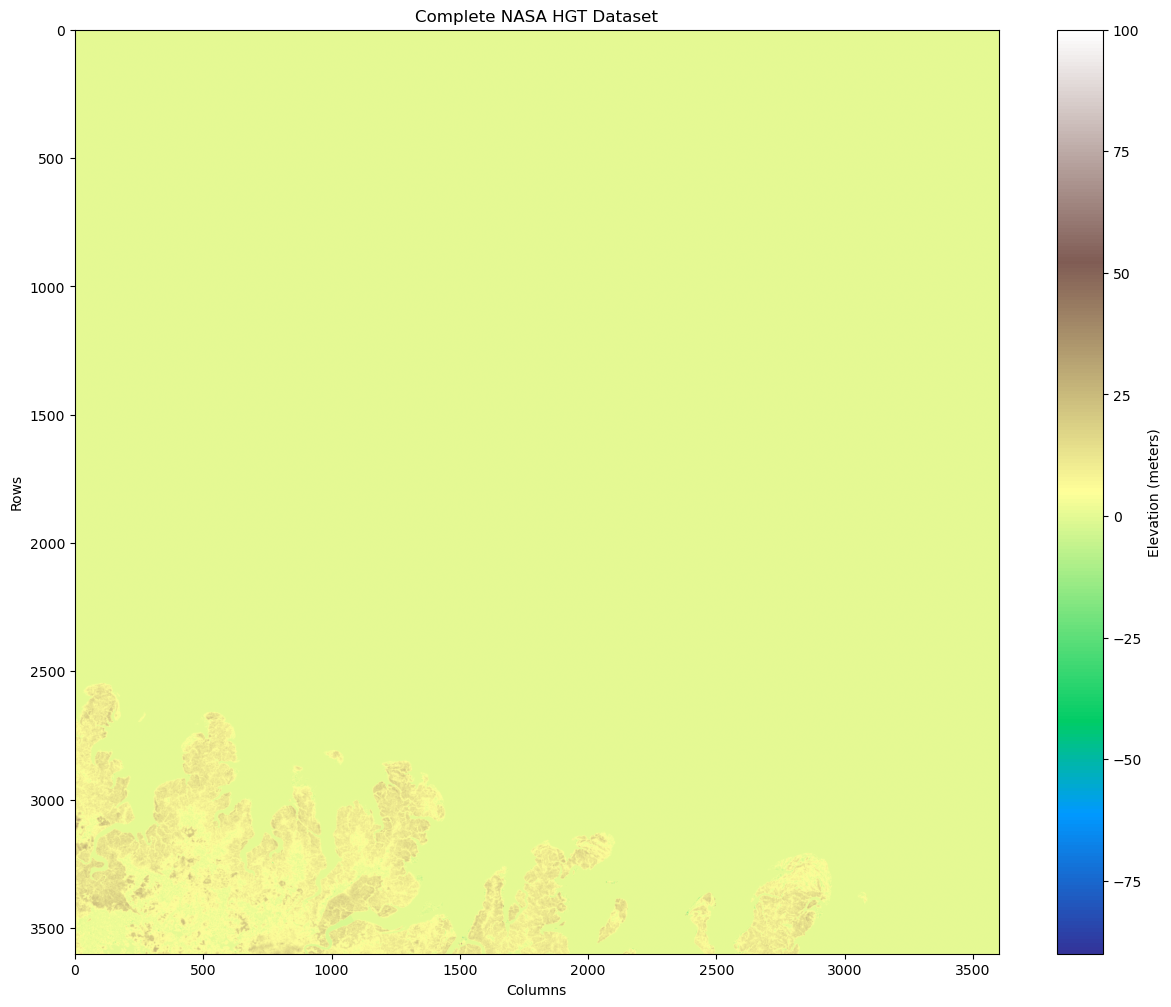

In [31]:
plt.figure(figsize=(15, 12))

plt.imshow(hgt, cmap='terrain')
plt.colorbar(label='Elevation (meters)')

plt.title('Complete NASA HGT Dataset')
plt.xlabel('Columns')
plt.ylabel('Rows')

plt.show()

In [32]:
print("HGT Information")
print("----------------")

print("Shape:", hgt.shape)
print("Data type:", hgt.dtype)

print("First 20 values:")
print(hgt[:20])

print("Minimum:", hgt.min())
print("Maximum:", hgt.max())
print("Mean:", hgt.mean())
print("Median:", np.median(hgt))

HGT Information
----------------
Shape: (3601, 3601)
Data type: >i2
First 20 values:
[[0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 ...
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]]
Minimum: -90
Maximum: 100
Mean: 0.7387407660296158
Median: 0.0


## HGT Dataset – Initial Data Exploration

### 1. Dataset Overview

The HGT file contains elevation-related raster data represented as a 2D NumPy array.

| Attribute | Value | Description |
|---|---:|---|
| Number of Rows | 3,601 | Total number of rows |
| Number of Columns | 3,601 | Total number of columns |
| Total Pixels | 12,967,201 | Total number of data points |
| Data Type | `>i2` | 16-bit signed integer (Big Endian) |
| Minimum Value | -90 | Lowest recorded value |
| Maximum Value | 100 | Highest recorded value |
| Mean | 0.739 | Average of all values |
| Median | 0 | Middle value after sorting all values |

### 2. Understanding the Results

- **Shape (3601 × 3601):** The dataset is organized as a grid containing 3,601 rows and 3,601 columns.
- **Total Pixels:** The grid contains 12,967,201 individual cells, where each cell represents a geographic location.
- **Data Type (`>i2`):** Each value is stored as a 16-bit signed integer using Big Endian byte order.
- **Minimum (-90) and Maximum (100):** These represent the lowest and highest values found in the dataset.
- **Mean (0.739):** The average value across all pixels is approximately 0.739.
- **Median (0):** The middle value of the dataset is zero, indicating that at least half of the observations are less than or equal to zero, and at least half are greater than or equal to zero.

### 3. Initial Observations

1. The dataset contains more than 12.9 million pixels.
2. The values range from -90 to 100.
3. The mean is greater than the median, suggesting that the distribution may be asymmetric.
4. The first displayed values are zeros, which makes it important to investigate how frequently zero occurs.
5. Zero values should not automatically be considered missing values because zero may represent a valid elevation.

`Next Step` ---> `EDA`

**Note:** These are preliminary observations. The physical meaning and units of the values must be verified before drawing geographical conclusions.

-------------------

### Step 1 — Data Distribution
I want to calculate the percentage of negative, positive and zeros values

In [33]:
total = hgt.size

zero_count = np.sum(hgt == 0)
negative_count = np.sum(hgt < 0)
positive_count = np.sum(hgt > 0)

print("Total Pixels:", total)

print("\nZero Values:")
print("Count:", zero_count)
print("Percentage:", zero_count / total * 100)

print("\nNegative Values:")
print("Count:", negative_count)
print("Percentage:", negative_count / total * 100)

print("\nPositive Values:")
print("Count:", positive_count)
print("Percentage:", positive_count / total * 100)

Total Pixels: 12967201

Zero Values:
Count: 11814588
Percentage: 91.1113200142421

Negative Values:
Count: 17179
Percentage: 0.13248040190014793

Positive Values:
Count: 1135434
Percentage: 8.756199583857766


`Zero dominates the dataset`

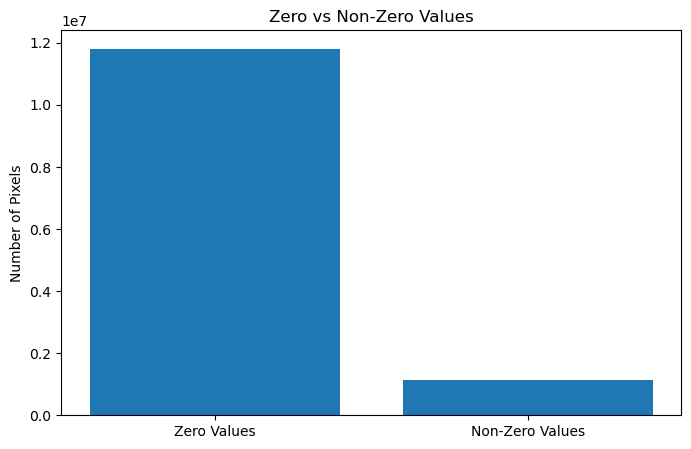

In [36]:
zero_count = np.count_nonzero(hgt == 0)
non_zero_count = np.count_nonzero(hgt != 0)

labels = ["Zero Values", "Non-Zero Values"]
counts = [zero_count, non_zero_count]

plt.figure(figsize=(8, 5))
plt.bar(labels, counts)

plt.title("Zero vs Non-Zero Values")
plt.ylabel("Number of Pixels")

save_path = os.path.join(
    PLOTS_PATH,
    "02_Zero_Values_Analysis",
    "zero_vs_nonzero.png"
)

plt.savefig(save_path, dpi=300, bbox_inches="tight")

plt.show()

ana 3ayza a3raf 3al el Zeros monta4era fe kol 7eta wala metgam3a fe makan?

Binary Mask:
- Black --> Zero Values
- White --> Non-Zeros Values

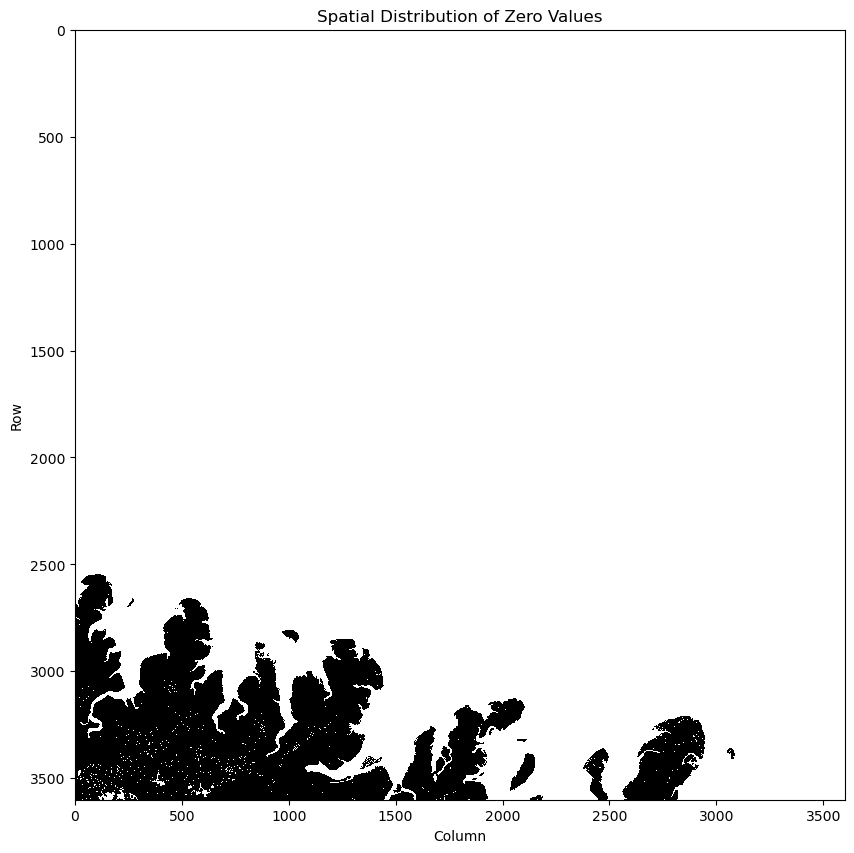

In [37]:
zero_mask = (hgt == 0)

plt.figure(figsize=(12, 10))

plt.imshow(zero_mask, cmap="gray", interpolation="nearest")

plt.title("Spatial Distribution of Zero Values")
plt.xlabel("Column")
plt.ylabel("Row")

plt.savefig(
    os.path.join(
        PLOTS_PATH,
        "02_Zero_Values_Analysis",
        "zero_spatial_distribution.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Row and Column Analysis

3alshan a4oof el distribution for every pixel (Row * Column)

In [38]:
# Calculate zero percentage for each row
zero_per_row = np.mean(hgt == 0, axis=1) * 100

# Calculate zero percentage for each column
zero_per_column = np.mean(hgt == 0, axis=0) * 100

print("Highest zero percentage in a row:",
      zero_per_row.max())

print("Lowest zero percentage in a row:",
      zero_per_row.min())

print("Highest zero percentage in a column:",
      zero_per_column.max())

print("Lowest zero percentage in a column:",
      zero_per_column.min())

Highest zero percentage in a row: 100.0
Lowest zero percentage in a row: 39.23910024993057
Highest zero percentage in a column: 100.0
Lowest zero percentage in a column: 71.59122465981672


`Primary Insights`

### Zero Values – Row and Column Analysis

The spatial distribution of zero values was further investigated by calculating their percentage across individual rows and columns.

**Results:**

| Metric | Percentage |
|---|---:|
| Maximum zero percentage per row | 100% |
| Minimum zero percentage per row | 39.24% |
| Maximum zero percentage per column | 100% |
| Minimum zero percentage per column | 71.59% |

**Initial Findings:**

- Zero values are present across all rows and columns.
- At least one row and one column consist entirely of zero values.
- Even the row and column with the lowest zero concentration contain a substantial proportion of zeros.
- The results suggest a potentially structured spatial distribution of zero values.

**Next Step:** Identify the exact locations of fully zero rows and columns, then investigate zero-value concentration across spatial blocks.

**Note:** These findings describe the numerical distribution only. The meaning of zero values has not yet been established.


In [39]:
# Find rows containing only zeros
full_zero_rows = np.where(zero_per_row == 100)[0]

# Find columns containing only zeros
full_zero_columns = np.where(zero_per_column == 100)[0]

print("Fully zero rows:", full_zero_rows)
print("Fully zero columns:", full_zero_columns)

print("Number of fully zero rows:", len(full_zero_rows))
print("Number of fully zero columns:", len(full_zero_columns))

Fully zero rows: [   0    1    2 ... 2540 2541 2542]
Fully zero columns: [2188 2189 2190 2191 2192 2193 2194 2195 2196 2197 2198 2199 2200 2201
 2202 2203 2204 2205 2206 2207 2208 2209 2210 2211 2212 2213 2214 2215
 2216 2217 2218 2219 2220 2221 2222 2223 2224 2225 2226 2227 2228 2229
 2230 2231 2232 2233 2234 2235 2236 2237 2238 2239 2240 2241 2242 2243
 2244 2245 2246 2247 2248 2249 2250 2251 2252 2253 2254 2255 2256 2257
 2258 2259 2260 2261 2262 2263 2264 2265 2266 2267 2268 2269 2270 2271
 2272 2273 2274 2275 2276 2277 2278 2279 2280 2281 2282 2283 2284 2285
 2286 2287 2288 2289 2290 2291 2292 2293 2294 2295 2296 2297 2298 2299
 2300 2301 2302 2303 2304 2305 2306 2307 2308 2309 2310 2311 2312 2313
 2314 2315 2316 2317 2318 2319 2320 2321 2322 2323 2324 2325 2326 2327
 2328 2329 2330 2331 2332 2333 2334 2335 2336 2337 2338 2339 2340 2341
 2342 2343 2344 2345 2346 2347 2348 2349 2350 2351 2352 2353 2354 2355
 2356 2357 2358 2359 2360 2361 2362 2363 2364 2365 2366 2367 2368 2369
 237

-----

## Start Again

In [40]:
for filename in os.listdir(DATA_PATH):

    file_path = os.path.join(DATA_PATH, filename)

    if os.path.isfile(file_path):

        file_size = os.path.getsize(file_path)

        print("File:", filename)
        print("Size:", file_size, "bytes")
        print("Size in MB:", round(file_size / (1024 ** 2), 2))
        print("-" * 40)

File: s01w047.hgt
Size: 25934402 bytes
Size in MB: 24.73
----------------------------------------
File: s01w047.num
Size: 12967201 bytes
Size in MB: 12.37
----------------------------------------
File: s01w047.swb
Size: 12967201 bytes
Size in MB: 12.37
----------------------------------------


In [41]:
num_path = os.path.join(DATA_PATH, "s01w047.num")
swb_path = os.path.join(DATA_PATH, "s01w047.swb")

num = np.fromfile(num_path, dtype=np.uint8)
swb = np.fromfile(swb_path, dtype=np.uint8)

print("NUM shape:", num.shape)
print("NUM dtype:", num.dtype)
print("NUM min:", num.min())
print("NUM max:", num.max())

print("\nSWB shape:", swb.shape)
print("SWB dtype:", swb.dtype)
print("SWB min:", swb.min())
print("SWB max:", swb.max())

NUM shape: (12967201,)
NUM dtype: uint8
NUM min: 0
NUM max: 250

SWB shape: (12967201,)
SWB dtype: uint8
SWB min: 0
SWB max: 255


In [42]:
print("NUM unique values:")
print(np.unique(num, return_counts=True))

print("\nSWB unique values:")
print(np.unique(swb, return_counts=True))

NUM unique values:
(array([  0,   1,   2,   3, 111, 112, 113, 114, 115, 117, 119, 123, 250],
      dtype=uint8), array([11801649,     1722,   776076,   387257,       79,      330,
             50,       12,        5,        1,        1,        3,
             16]))

SWB unique values:
(array([  0, 255], dtype=uint8), array([ 1165552, 11801649]))


In [43]:
num = num.reshape(3601, 3601)
swb = swb.reshape(3601, 3601)

print("HGT:", hgt.shape)
print("NUM:", num.shape)
print("SWB:", swb.shape)

HGT: (3601, 3601)
NUM: (3601, 3601)
SWB: (3601, 3601)


In [44]:
print("SWB unique values and counts:")
values, counts = np.unique(swb, return_counts=True)

for value, count in zip(values, counts):
    print(f"Value {value}: {count:,} pixels ({count / swb.size * 100:.2f}%)")

SWB unique values and counts:
Value 0: 1,165,552 pixels (8.99%)
Value 255: 11,801,649 pixels (91.01%)


In [45]:
zero_elevation = (hgt == 0)
water_mask = (swb == 255)

print("Zero elevation pixels:", zero_elevation.sum())
print("Water pixels:", water_mask.sum())

print("Zero elevation AND water:",
      np.sum(zero_elevation & water_mask))

print("Zero elevation AND land:",
      np.sum(zero_elevation & ~water_mask))

print("Non-zero elevation AND water:",
      np.sum((hgt != 0) & water_mask))

Zero elevation pixels: 11814588
Water pixels: 11801649
Zero elevation AND water: 11797296
Zero elevation AND land: 17292
Non-zero elevation AND water: 4353


In [46]:
total_pixels = hgt.size

groups = {
    "Zero + Water": np.sum((hgt == 0) & (swb == 255)),
    "Zero + Land": np.sum((hgt == 0) & (swb == 0)),
    "Non-zero + Water": np.sum((hgt != 0) & (swb == 255)),
    "Non-zero + Land": np.sum((hgt != 0) & (swb == 0))
}

for name, count in groups.items():
    print(
        f"{name}: {count:,} "
        f"({count / total_pixels * 100:.3f}%)"
    )

print("\nTotal:", sum(groups.values()))
print("Expected:", total_pixels)

Zero + Water: 11,797,296 (90.978%)
Zero + Land: 17,292 (0.133%)
Non-zero + Water: 4,353 (0.034%)
Non-zero + Land: 1,148,260 (8.855%)

Total: 12967201
Expected: 12967201


### HGT, NUM, and SWB Relationship Analysis

**Key Findings:**

1. All three datasets contain 12,967,201 pixels and can be reshaped into 3601 × 3601 grids.

2. The SWB dataset classifies approximately 91.01% of the pixels as water and 8.99% as land.

3. The NUM dataset contains source information about the elevation measurements, including SRTM, ASTER GDEM, and interpolated data.

4. The number of pixels with NUM = 0 exactly matches the number of water pixels in SWB (11,801,649), confirming consistency between the two water classifications.

5. Most zero-elevation pixels are classified as water. However, some zero-elevation pixels are classified as land, so zero elevation should not automatically be considered missing data.

6. A small number of pixels have non-zero elevations despite being classified as water. These cases require further investigation.

**Conclusion:**

The SWB layer can be used to distinguish land from water, while the NUM layer provides information about the source of elevation measurements. Both layers will be useful for validating and preprocessing the HGT elevation data before terrain feature extraction.

In [47]:
# Compare NUM and SWB classifications

num_water = (num == 0)
swb_water = (swb == 255)

print("NUM water pixels:", np.sum(num_water))
print("SWB water pixels:", np.sum(swb_water))

print("Both classify as water:",
      np.sum(num_water & swb_water))

print("NUM water but SWB land:",
      np.sum(num_water & ~swb_water))

print("SWB water but NUM not water:",
      np.sum(~num_water & swb_water))

print("Exact pixel agreement:",
      np.mean(num_water == swb_water) * 100, "%")

NUM water pixels: 11801649
SWB water pixels: 11801649
Both classify as water: 11801649
NUM water but SWB land: 0
SWB water but NUM not water: 0
Exact pixel agreement: 100.0 %


In [48]:
land_mask = (swb == 0)

land_elevation = hgt[land_mask]

print("Total land pixels:", land_elevation.size)

print("Minimum:", land_elevation.min())
print("Maximum:", land_elevation.max())
print("Mean:", land_elevation.mean())
print("Median:", np.median(land_elevation))

print("Zero elevation on land:", np.sum(land_elevation == 0))
print("Negative elevation on land:", np.sum(land_elevation < 0))
print("Positive elevation on land:", np.sum(land_elevation > 0))

Total land pixels: 1165552
Minimum: -90
Maximum: 100
Mean: 8.224719274644118
Median: 8.0
Zero elevation on land: 17292
Negative elevation on land: 13118
Positive elevation on land: 1135142


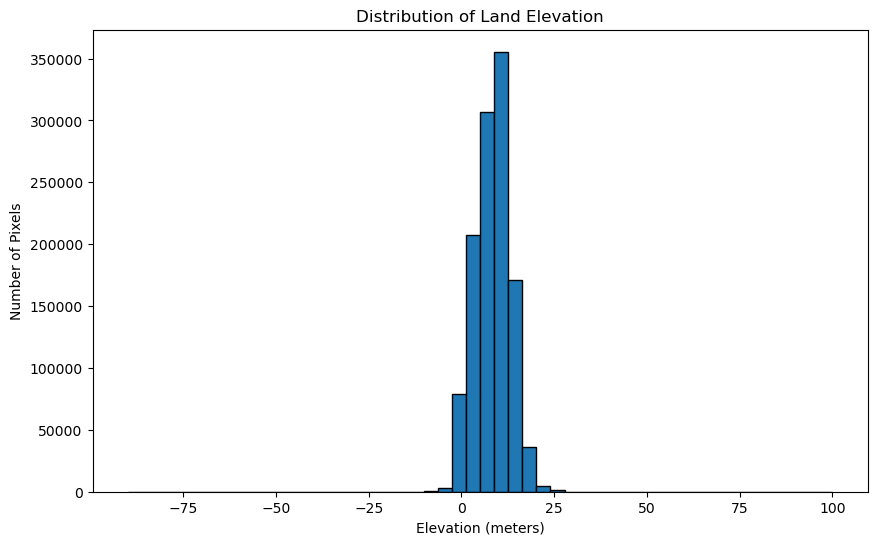

In [49]:
plt.figure(figsize=(10, 6))

plt.hist(
    land_elevation,
    bins=50,
    edgecolor="black"
)

plt.title("Distribution of Land Elevation")
plt.xlabel("Elevation (meters)")
plt.ylabel("Number of Pixels")

plt.savefig(
    os.path.join(
        PLOTS_PATH,
        "01_Initial_Exploration",
        "land_elevation_histogram.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


`Land Elevation Histogram`

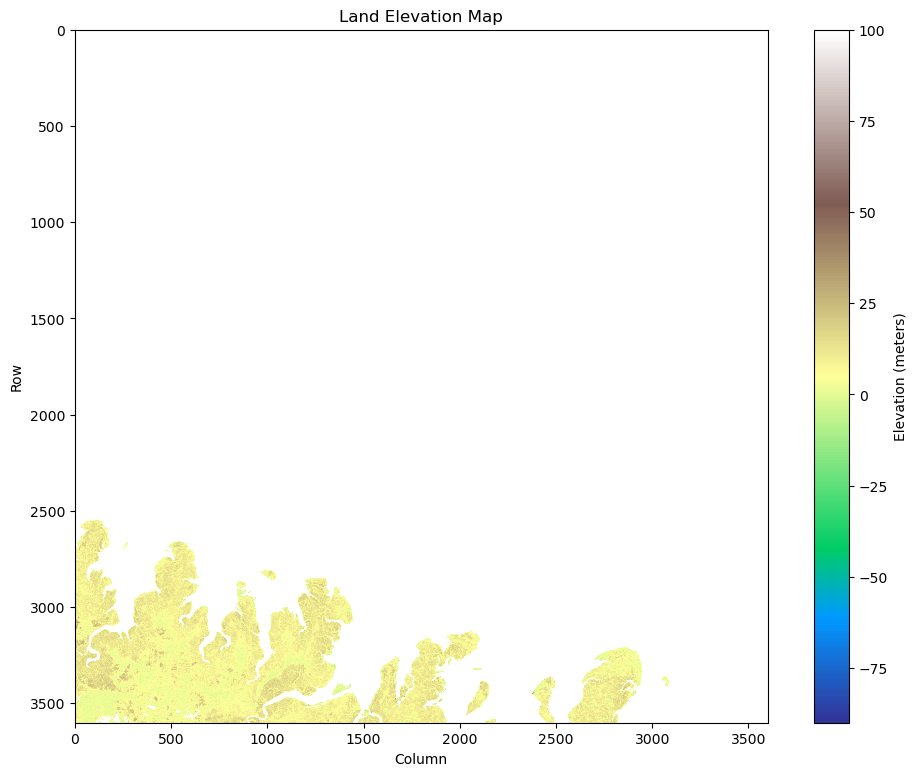

In [50]:
land_elevation_map = np.ma.masked_where(
    swb != 0,
    hgt
)

plt.figure(figsize=(12, 9))

plt.imshow(
    land_elevation_map,
    cmap="terrain",
    interpolation="nearest"
)

plt.colorbar(label="Elevation (meters)")

plt.title("Land Elevation Map")
plt.xlabel("Column")
plt.ylabel("Row")

plt.savefig(
    os.path.join(
        PLOTS_PATH,
        "01_Initial_Exploration",
        "land_elevation_map.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

`Land Elevation Map`

White ---> Water 

so instead of this, I will try to make water represeanted in blue

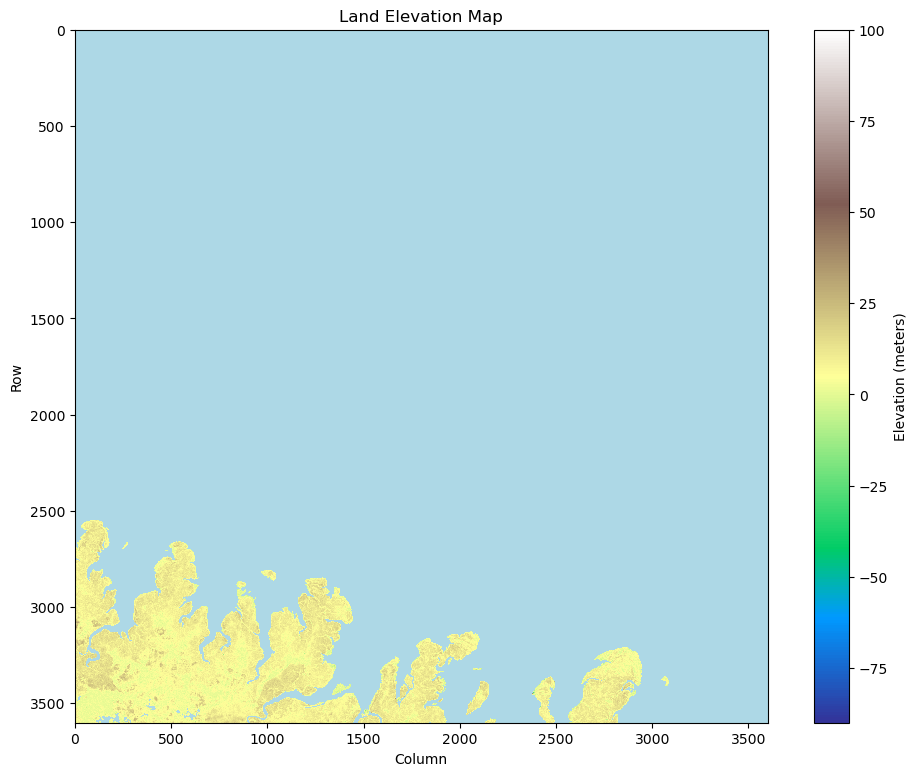

In [51]:
cmap = plt.colormaps["terrain"].copy()
cmap.set_bad(color="lightblue")

plt.figure(figsize=(12, 9))

plt.imshow(
    land_elevation_map,
    cmap=cmap,
    interpolation="nearest"
)

plt.colorbar(label="Elevation (meters)")
plt.title("Land Elevation Map")
plt.xlabel("Column")
plt.ylabel("Row")

plt.show()

In [52]:
# Approximate pixel spacing in meters
pixel_size = 30.9

# Calculate elevation change in both directions
dz_dy, dz_dx = np.gradient(
    hgt.astype(float),
    pixel_size,
    pixel_size
)

# Calculate slope in radians
slope_radians = np.arctan(
    np.sqrt(dz_dx**2 + dz_dy**2)
)

# Convert radians to degrees
slope_degrees = np.degrees(slope_radians)

# Mask water pixels
slope_map = np.ma.masked_where(
    swb != 0,
    slope_degrees
)

print("Minimum slope:", slope_map.min())
print("Maximum slope:", slope_map.max())
print("Mean slope:", slope_map.mean())
print("Median slope:", np.ma.median(slope_map))

Minimum slope: 0.0
Maximum slope: 60.42620711917002
Mean slope: 2.7133833805854963
Median slope: 2.072190825000368


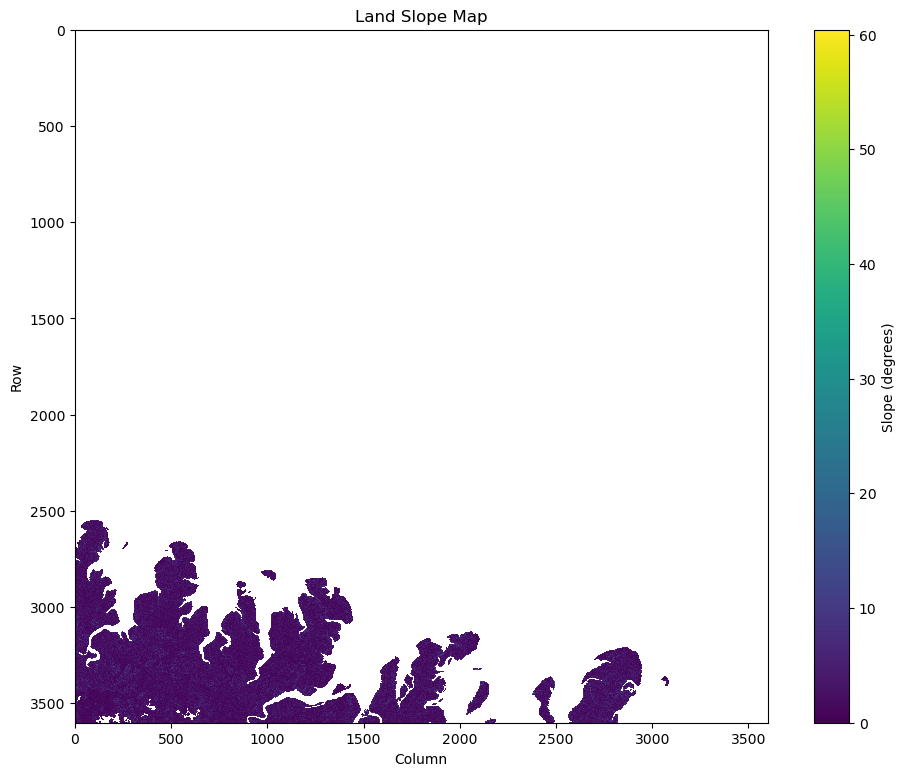

In [53]:
plt.figure(figsize=(12, 9))

plt.imshow(
    slope_map,
    cmap="viridis",
    interpolation="nearest"
)

plt.colorbar(label="Slope (degrees)")

plt.title("Land Slope Map")
plt.xlabel("Column")
plt.ylabel("Row")

plt.savefig(
    os.path.join(
        PLOTS_PATH,
        "05_Spatial_Analysis",
        "land_slope_map.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()